In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import sklearn as sk
from sklearn import datasets, linear_model
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
df = pd.read_csv("dummy_hr_data.csv")
df

,Time,Value
0,2019-11-01 00:00:00,70.125000
1,2019-11-01 00:01:00,67.555556
2,2019-11-01 00:02:00,70.000000
3,2019-11-01 00:04:00,67.875000
4,2019-11-01 00:05:00,67.400000
...,...,...
851,2019-11-01 15:04:00,63.000000
852,2019-11-01 15:05:00,63.333333
853,2019-11-01 15:06:00,67.428571
854,2019-11-01 15:07:00,81.571429


In [4]:
df.dtypes

Time         str
Value    float64
dtype: object

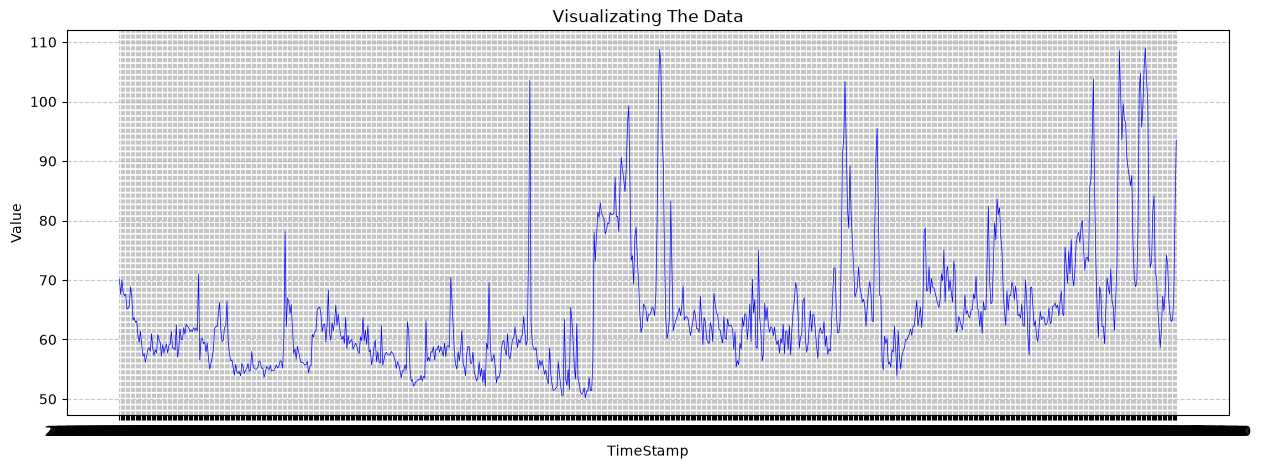

In [5]:

plt.figure(figsize=(15, 5))

plt.plot(df["Time"], df["Value"], color = "blue", linewidth = 0.5)

plt.title("Visualizating The Data")

plt.xlabel("TimeStamp")
plt.ylabel("Value")

plt.grid(True, linestyle='--', alpha = 0.7)

plt.show()

In [13]:
train_data, test_data = train_test_split(df[["Value"]], test_size=0.2, shuffle = False)

In [14]:
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train_data)
scaled_test = scaler.transform(test_data)

In [15]:
def sliding_window(dataset, window_size = 10):
    X, y = [], []

    for i in range(len(dataset) - window_size):
        X.append(dataset[i:(i+window_size), 0])
        y.append(dataset[i + window_size, 0])

    return np.array(X), np.array(y)

In [16]:
window_size = 10

X_train, y_train = sliding_window(scaled_train, window_size)
X_test, y_test = sliding_window(scaled_test, window_size)

print(f"X_train shape: {X_train.shape} (Rows, 10 inputs)")
print(f"y_train shape: {y_train.shape} (Rows, 1 output)")

X_train shape: (674, 10) (Rows, 10 inputs)
y_train shape: (674,) (Rows, 1 output)


In [17]:
mlp_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation = "relu",
    solver = 'adam',
    max_iter = 500,
    random_state = 42
)

print("Training the MLP model...")
mlp_model.fit(X_train, y_train)
print("Training done!")

predict = mlp_model.predict(X_test)
predictions = scaler.inverse_transform(predict.reshape(-1, 1))
actual_y_test = scaler.inverse_transform(y_test.reshape(-1, 1))

Training the MLP model...
Training done!


In [18]:
mean_absolute = mean_absolute_error(actual_y_test, predictions)

mean_squared = mean_squared_error(actual_y_test, predictions)
rmse = np.sqrt(mean_squared)

print(f"Mean Absolute Error (MAE): {mean_absolute:.2f} BPM")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} BPM")

Mean Absolute Error (MAE): 4.72 BPM
Root Mean Squared Error (RMSE): 6.67 BPM


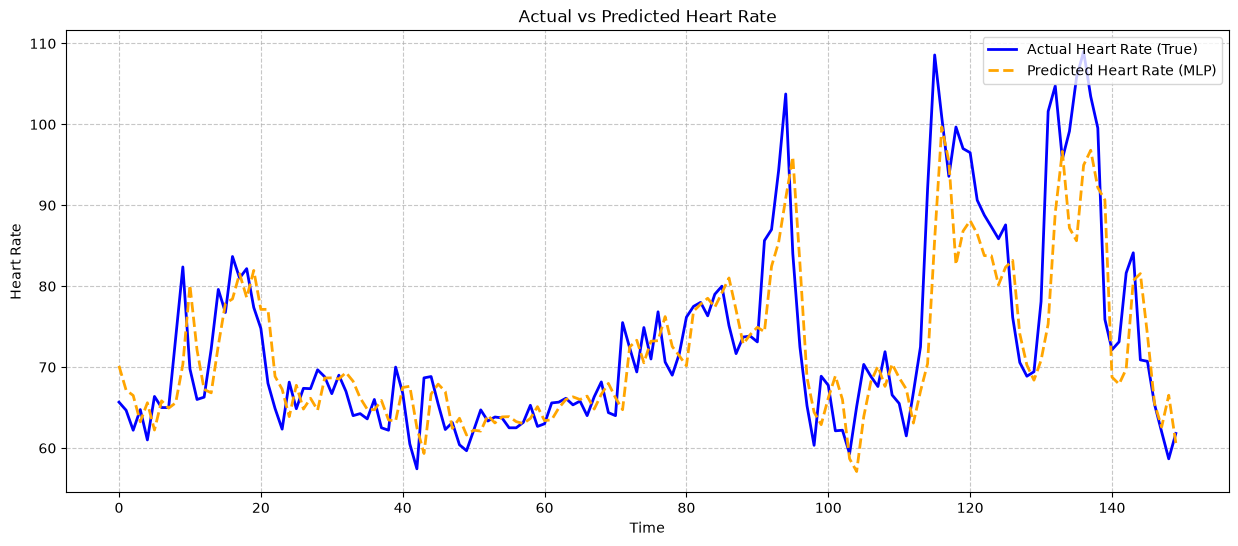

In [19]:
plt.figure(figsize=(15, 6))

plot_limit = 150

plt.plot(actual_y_test[:plot_limit], label="Actual Heart Rate (True)", color="blue", linewidth=2)
plt.plot(predictions[:plot_limit], label="Predicted Heart Rate (MLP)", color="orange", linestyle="--", linewidth=2)

plt.title("Actual vs Predicted Heart Rate")
plt.xlabel("Time")
plt.ylabel("Heart Rate")

plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()